<a href="https://colab.research.google.com/github/AnuMaryJohn/Data-Science---Python/blob/main/Python_Module_End_Assessment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import pandas as pd

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
sns.set(style="darkgrid")

In [11]:
%matplotlib inline

In [12]:
import warnings
warnings.filterwarnings("ignore")

# **Preprocessing**

In [13]:
df=pd.read_excel("ABC Company.xlsx")
df.head(10)

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2023-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2023-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2023-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2023-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2023-10-06 00:00:00,231,NaN,5000000.0
5,Amir Johnson,Boston Celtics,90,PF,29,2023-09-06 00:00:00,240,NaN,12000000.0
6,Jordan Mickey,Boston Celtics,55,PF,21,2023-08-06 00:00:00,235,LSU,1170960.0
7,Kelly Olynyk,Boston Celtics,41,C,25,7-0,238,Gonzaga,2165160.0
8,Terry Rozier,Boston Celtics,12,PG,22,2023-02-06 00:00:00,190,Louisville,1824360.0
9,Marcus Smart,Boston Celtics,36,PG,22,2023-04-06 00:00:00,220,Oklahoma State,3431040.0


In [14]:
df.isnull().sum()

,0
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 32.3+ KB


In [16]:
df["Height"]=np.random.randint(150,180,458)
df.head()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,150,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,178,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,164,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,153,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,154,231,NaN,5000000.0


To ensure the consistency and integrity of the data.

In [17]:
df['Height'].describe()

,Height
count,458.000000
mean,164.242358
std,8.443673
min,150.000000
25%,157.000000
50%,164.000000
75%,172.000000
max,179.000000


# **Analysis and Interpretation**

## **Question 1**

### Determine the distribution of employees across each team and calculate the percentage split relative to the total number of employees.

In [18]:
table=df['Team'].value_counts().reset_index(name='count')

In [19]:
table=pd.DataFrame(table)

In [20]:
table['Percentage']=(table['count']/len(df))*100
df1=pd.DataFrame(table)
df1

,Team,count,Percentage
0,New Orleans Pelicans,19,4.148472
1,Memphis Grizzlies,18,3.930131
2,Utah Jazz,16,3.493450
3,Milwaukee Bucks,16,3.493450
4,New York Knicks,16,3.493450
5,Boston Celtics,15,3.275109
6,Los Angeles Clippers,15,3.275109
7,Los Angeles Lakers,15,3.275109
8,Phoenix Suns,15,3.275109
9,Sacramento Kings,15,3.275109


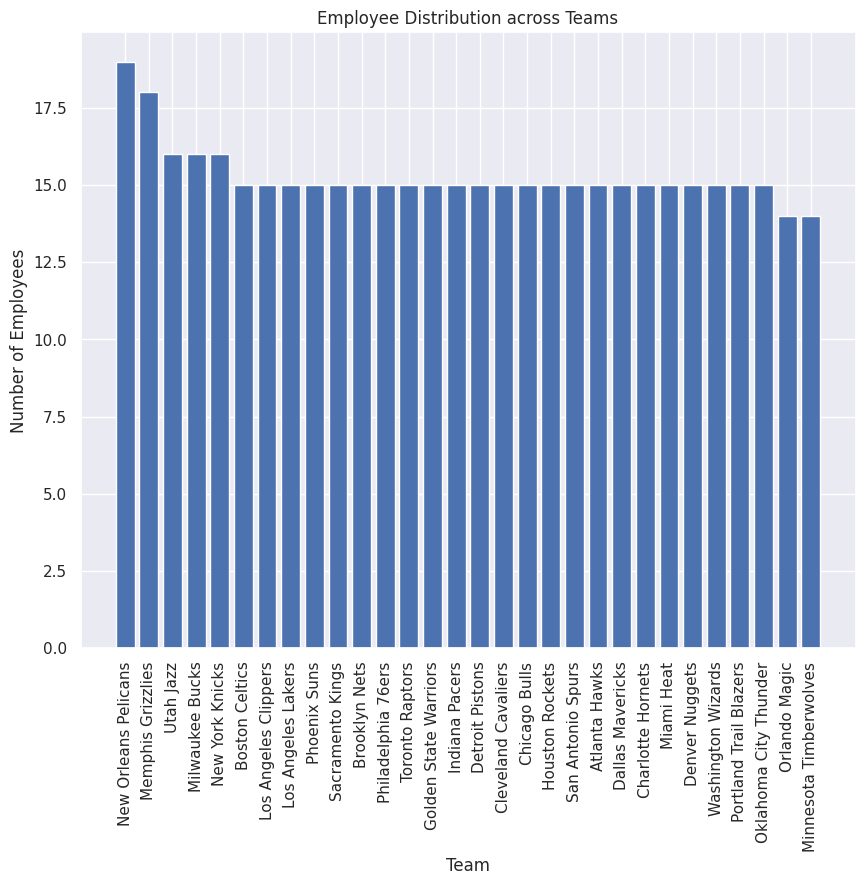

In [21]:
plt.figure(figsize=(10,8))
plt.bar(df1['Team'],df1['count'])
plt.title("Employee Distribution across Teams")
plt.xlabel("Team")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)
plt.show()

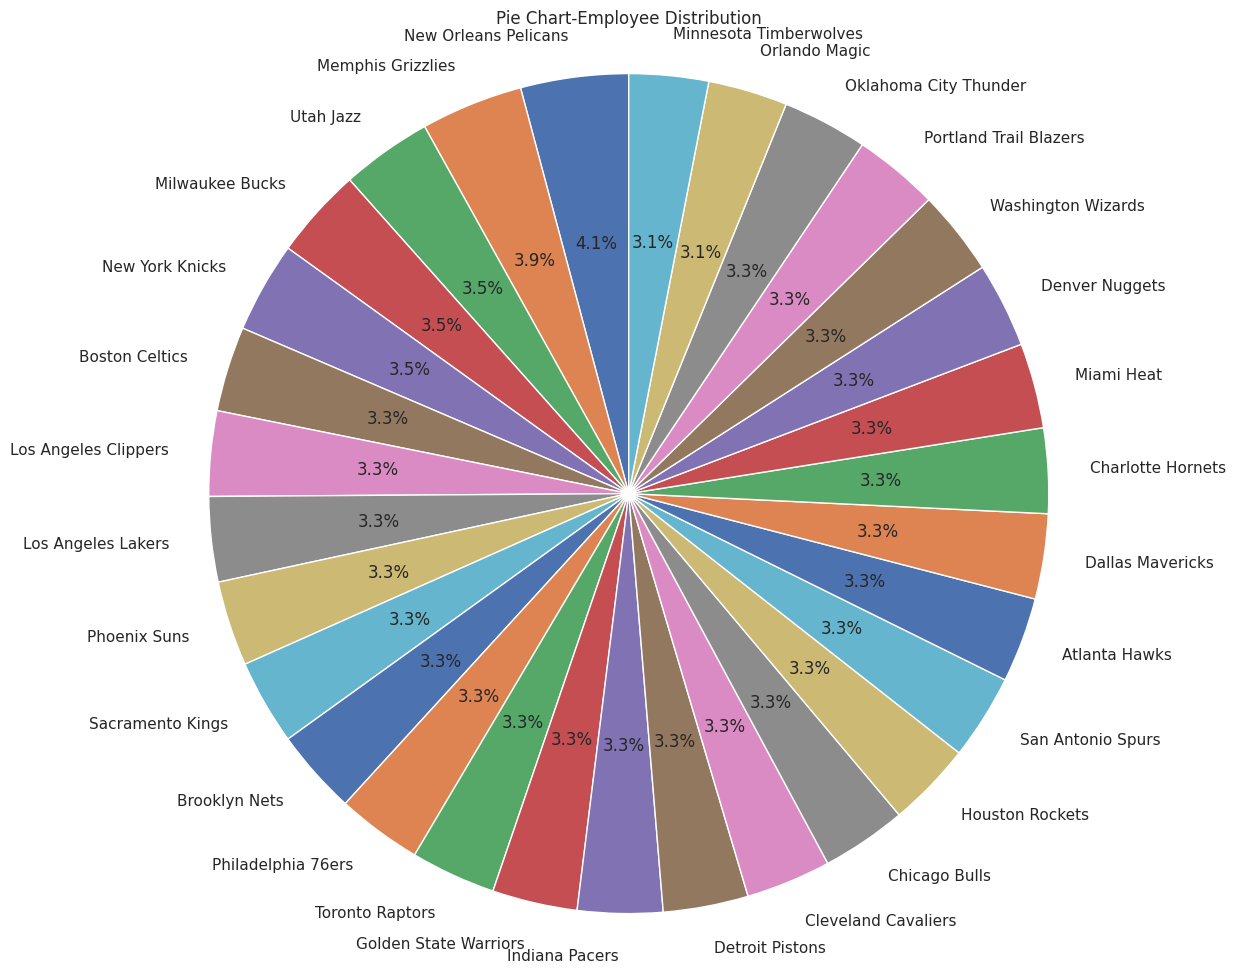

In [22]:
plt.figure(figsize=(14,12))
plt.pie(df1['count'],labels=df1['Team'], autopct='%.1f%%',shadow=False,startangle=90)
plt.title('Pie Chart-Employee Distribution')
plt.axis('equal')
plt.show()

OR

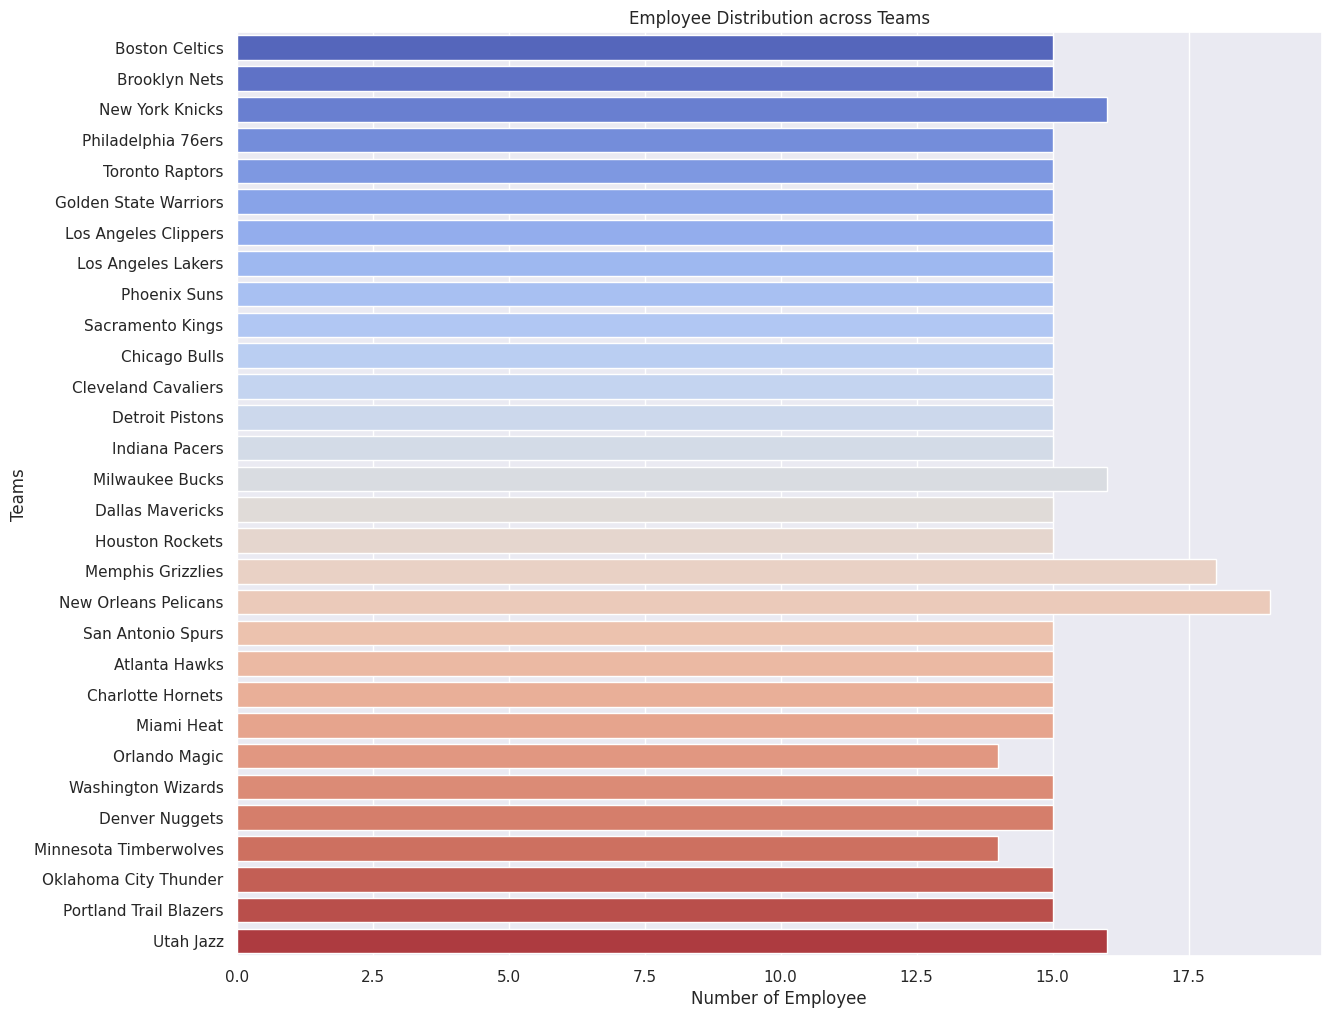

In [23]:
plt.figure(figsize=(14,12))
sns.countplot(y='Team',data=df,palette='coolwarm')
plt.title("Employee Distribution across Teams")
plt.ylabel("Teams")
plt.xlabel('Number of Employee')
plt.show()

Insights: The Team with the maximum number of teammates is New Orleans Pelicans with 19 members, which consist almost 4.14% of the total employees and the team with the least number of teammates is Minnesota Timberwolves and Orlando Magic with 14 menbers each, which constitutes 3.05% of total employess. There are a total of 30 teams.

## **Question 2**

### Segregate employees based on their positions within the company.

In [24]:
table=df['Position'].value_counts().reset_index(name='count')

In [25]:
df2=pd.DataFrame(table)
df2

,Position,count
0,SG,102
1,PF,100
2,PG,92
3,SF,85
4,C,79


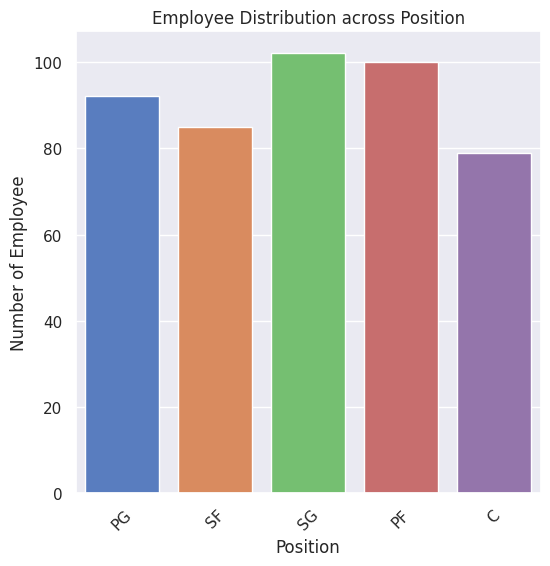

In [26]:
plt.figure(figsize=(6,6))
sns.countplot(x='Position',data=df,palette='muted')
plt.title("Employee Distribution across Position")
plt.xlabel("Position")
plt.ylabel('Number of Employee')
plt.xticks(rotation=45)
plt.show()

OR

In [27]:
counts = df['Position'].value_counts()
print(counts)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


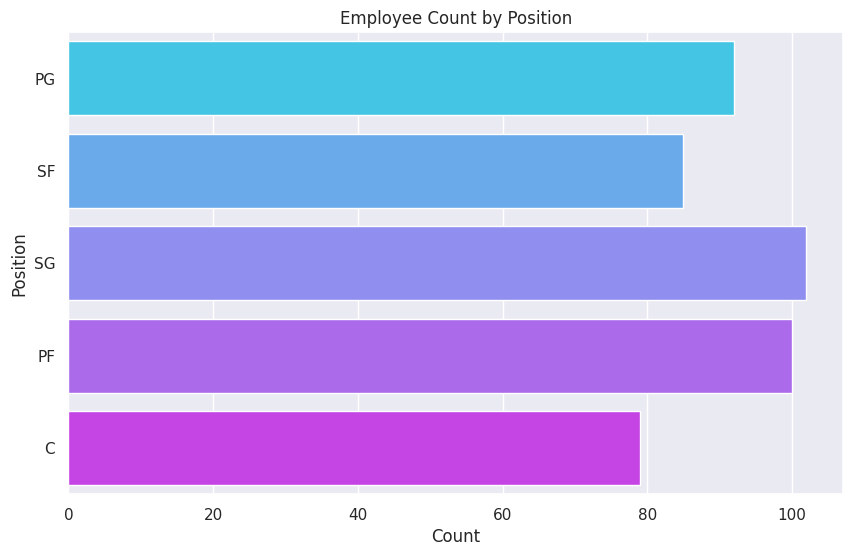

In [28]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='Position', palette='cool')
plt.title('Employee Count by Position')
plt.xlabel('Count')
plt.ylabel('Position')
plt.show()

Insights: A total of 458 employess works in the company in different positions, of which 102 employess works as SG which is the max number of employees working in a position. The minimum number of employees working in a position is 79 which is position c.

## **Question 3**

### Identify the predominant age group among employees.

To get the value count of each age. From this we can identify the most repeated age.

In [29]:
counts=df['Age'].value_counts()
counts

,count
Age,
24,47
25,46
27,41
23,41
26,36
30,31
28,31
29,28
22,26


To identify the most prominant age, we can use mode function.

In [30]:
df['Age'].mode()

,Age
0,24


To identify the most prominant age group, we can use the histogram. From the figure we can identify the most prominant agr group by looking at the height of the bars.

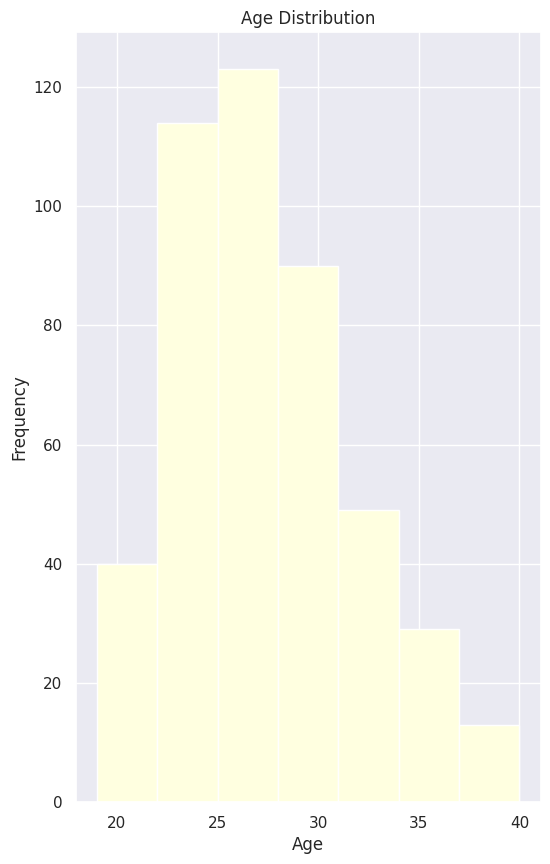

In [31]:
plt.figure(figsize = (6,10))
plt.hist(df['Age'],bins=7,color='lightyellow')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

OR

<Figure size 600x1000 with 0 Axes>

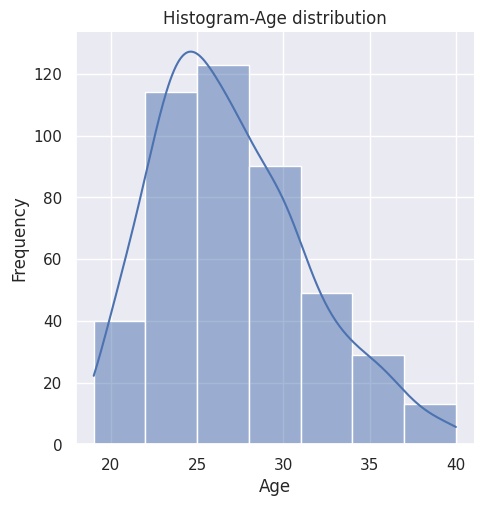

In [32]:
plt.figure(figsize = (6,10))
sns.displot(df['Age'],bins=7,kde=True)
plt.title("Histogram-Age distribution")
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Insights: The most prominant age is 24 with 47 employees, and the data is divided into 7 bins and the most prominant age group is 25-27. Also the age data is skewed(positively).

## **Question 4**

### Discover which team and position have the highest salary expenditure.

To complete this task first we have to clean the data by droping the null values, as salary has 11 null values.

In [33]:
df4=df.dropna(subset=['Team','Position','Salary'])

In [34]:
df4[['Team','Position','Salary']].isnull().sum()

,0
Team,0
Position,0
Salary,0


In [35]:
df5 = df.groupby(['Team', 'Position'])['Salary'].sum().reset_index()
df5.head()

,Team,Position,Salary
0,Atlanta Hawks,C,22756250.0
1,Atlanta Hawks,PF,23952268.0
2,Atlanta Hawks,PG,9763400.0
3,Atlanta Hawks,SF,6000000.0
4,Atlanta Hawks,SG,10431032.0


To Find the Team with the highest salary expenditure.

In [36]:
team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)
sal_by_tm=pd.DataFrame(team_salary)

In [37]:
print(sal_by_tm[sal_by_tm['Salary']==sal_by_tm['Salary'].max()])

                          Salary
Team                            
Cleveland Cavaliers  106988689.0


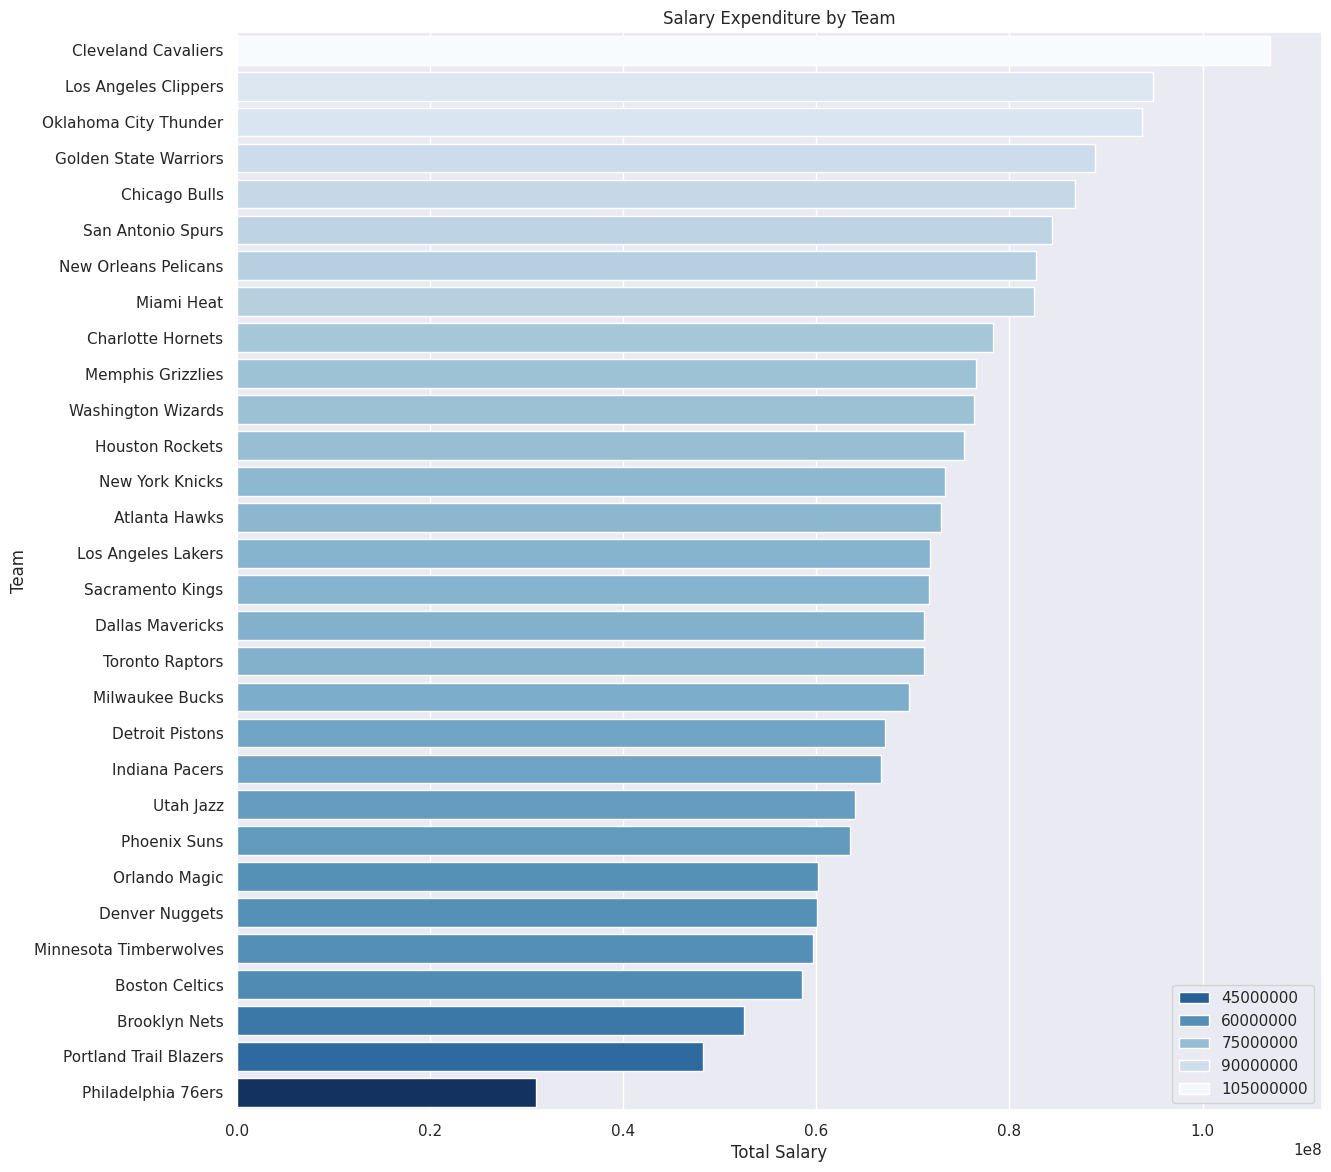

In [38]:
plt.figure(figsize = (14,14))
sns.barplot(x=team_salary.values, y=team_salary.index,hue=team_salary.values, palette='Blues_r')
plt.title('Salary Expenditure by Team')
plt.xlabel('Total Salary')
plt.show()

To Find the Position with the highest salary expenditure.

In [39]:
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)
sal_by_pos=pd.DataFrame(position_salary)

In [40]:
print(sal_by_pos[sal_by_pos['Salary']==sal_by_pos['Salary'].max()])

               Salary
Position             
C         466377332.0


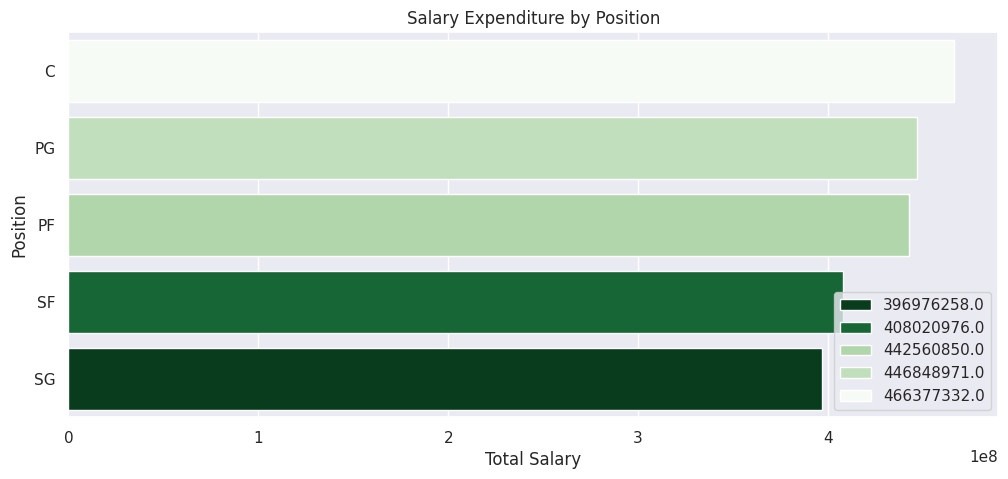

In [41]:
plt.figure(figsize = (12,5))
sns.barplot(x=position_salary.values, y=position_salary.index,hue=position_salary.values, palette='Greens_r')
plt.title('Salary Expenditure by Position')
plt.xlabel('Total Salary')
plt.show()

OR

In [42]:
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False).reset_index(name='salary_sum')
data=pd.DataFrame(position_salary)

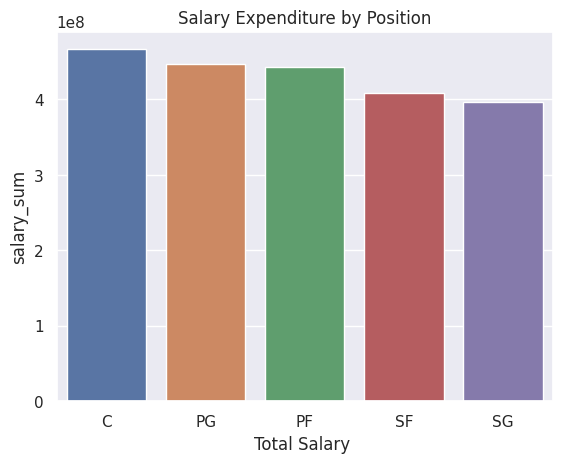

In [43]:
sns.barplot(x="Position", y="salary_sum",data=data,hue="Position")
plt.title('Salary Expenditure by Position')
plt.xlabel('Total Salary ')
plt.show()

Now to Find the team and position with highest salary expenditure.

In [44]:
print(df5[df5['Salary'] == df5['Salary'].max()])

                  Team Position      Salary
67  Los Angeles Lakers       SF  31866445.0


<Figure size 1400x1400 with 0 Axes>

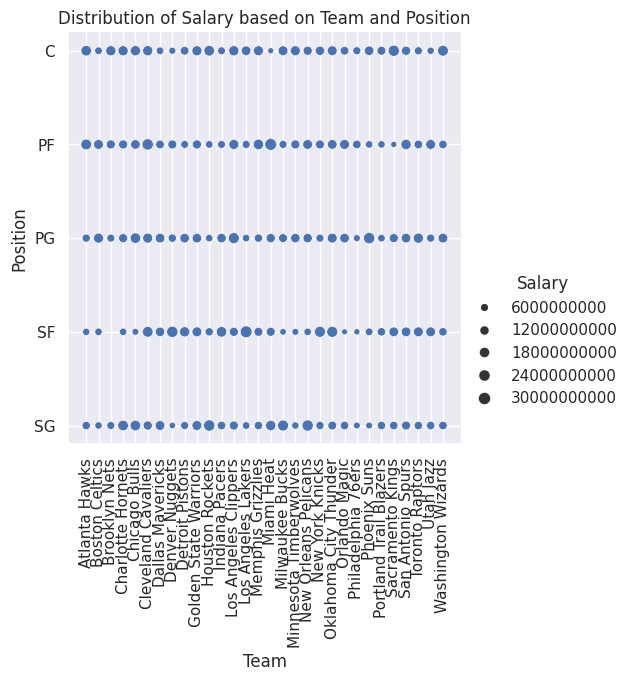

In [45]:
plt.figure(figsize = (14,14))
sns.relplot(x='Team',y='Position',size=df5['Salary']*1000, data=df5, palette='bright',kind="scatter");
plt.title('Distribution of Salary based on Team and Position')
plt.xlabel('Team')
plt.ylabel('Position')
plt.xticks(rotation=90)
plt.show()

Insights: If we are looking for the team with the highest salary expenditure: team Cleveland Cavaliers has highest salary expendure of 106988689, which is not the team with highest number of members. If we are looking for the position with the highest salary expenditure: position C has highest salary expenditure of 466377332, which is the position with least number of employees. But if we are looking for the team and position together of highest salary expenditure: we can find, from team Los Angeles Lakers with Position SF has the highest Salary expenditure of 31866445.

## **Question 5**

### Investigate if there's any correlation between age and salary, and represent it visually.

To complete this task first we have to clean the data by droping the null values, as salary has 11 null values.

In [46]:
df6=df.dropna(subset=['Age','Salary'])

In [47]:
df6[['Age','Salary']].isnull().sum()

,0
Age,0
Salary,0


In [48]:
df7=df6[['Age','Salary']]
df7.head()

,Age,Salary
0,25,7730337.0
1,25,6796117.0
3,22,1148640.0
4,29,5000000.0
5,29,12000000.0


In [49]:
corr=df7.corr()
corr

,Age,Salary
Age,1.000000,0.214009
Salary,0.214009,1.000000


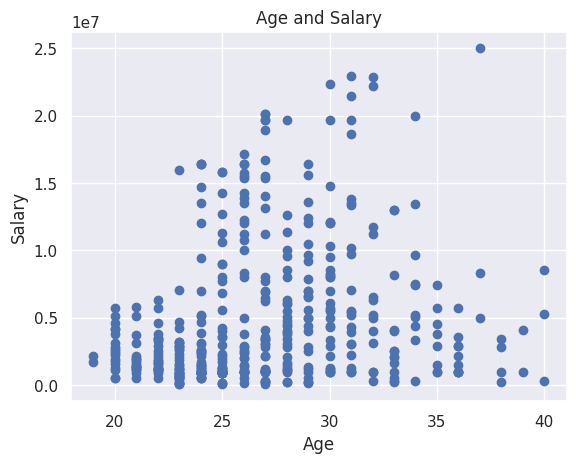

In [50]:
plt.scatter(df7["Age"], df7["Salary"])
plt.title("Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

OR

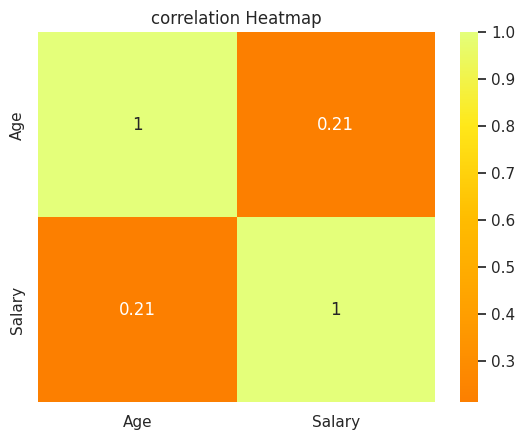

In [51]:
sns.heatmap(corr,annot=True,cmap='Wistia_r')
plt.title('correlation Heatmap')
plt.show()

Insights: The scatter diagram doesnot show any pattern, which indicates that there is no conclusive evidence for a correlation between Age and Salary. The correlation value shows that there is a slight positive correlation netween Age and Salary but since the value is between 0 and 0.5, it is not significant so, we can conclude that there is no correlation between Age and Salary.